# Using Diffusion on prediction of video and motion

## Import the lib and initialize the parameters

In [ ]:
import argparse
import os.path

import torch
from torch import nn,optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset
import torch.nn.functional as F



In [17]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
# parser.add_argument('--data_path', type=str, default='dataset/2024-10-31_xacti_5fps')
# parser.add_argument('--data_path', type=str, default='dataset/ATR_1F_3F_2024-12-25_withtest')
parser.add_argument('--data_path', type=str, default='dataset/ATR_1F_3F_2024-12-25')

# parser.add_argument('--data_path', type=str, default='dataset/mul_fps_data')

parser.add_argument('--sequence_length', type=int, default=40)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])
mulgpu = True
rgb = False

cuda


## 1. Load the Dataset

In [18]:
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=rgb, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length,rgb=rgb, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl


metadata exists in: dataset/ATR_1F_3F_2024-12-25/test/metadata_40.pkl


## 2. Load the networks

In [19]:
from utils import fw_diffusion_vid, fw_diffusion_mot, MixedSequenceMaskGenerator
input_mot_channel = args.sequence_length * 2
mask_generator = MixedSequenceMaskGenerator(t2=args.sequence_length)

# The parameters for forward diffusion process
beta = torch.linspace(1e-4, 0.02, args.iteration_num) 
alpha = 1.0-beta
alpha_cum = torch.tensor([alpha[0]] + [torch.prod(alpha[:i+1]) for i in range(1, len(beta))])

## 3. Train the model

### 3.1 Continue from the checkpoint

In [20]:
from TimeSformer.VDT_cat_vm import VDT_cat

nhead = 6
depth = 12
patch_size= 2
hidden_size = 768
epoch = 100
in_channels = 6
input_size = 8

eps_est_model = VDT_cat(
    input_size=input_size,
    patch_size=patch_size,
    in_channels=in_channels,
    hidden_size=hidden_size,
    depth=depth,
    num_frames=args.sequence_length,
    num_heads=nhead,
    mlp_ratio=4.0,
    learn_sigma=False
    ).to(DEVICE)


from diffusers.models import AutoencoderKL
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(DEVICE)
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)


if mulgpu:
    input_dim = 3
    modelData = 'checkpoints_vae_3c_seg/vae_20250202_seg40.pth.tar'
    checkpoint = torch.load(modelData)
    state_dict = checkpoint['model_state_dict']
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
else:
    modelData = 'checkpoints_vae_seg/vae_40.pth.tar'
    checkpoint = torch.load(modelData)
    state_dict = checkpoint['model_state_dict']
        

vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse")
vae.encoder.conv_in = nn.Conv2d(input_dim, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, input_dim, kernel_size=3, stride=1, padding=1)
vae.load_state_dict(state_dict)
vae.to(DEVICE)

# freeze vae
for param in vae.parameters():
    param.requires_grad = False



In [8]:
sum([p.numel() for p in eps_est_model.parameters()])

165333906

## 4. Tests

### 4.1 DDIM for generation

In [8]:
valid_dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

metadata exists in: dataset/ATR_1F_3F_2024-12-25_withtest/train/metadata_40.pkl


In [ ]:
from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray2color
import time

modelData = '/home/xu/xu/mmVDT_robo_nav/checkpoints_mmVDT_vae_3c_seg/VDT_20250203_ATR_1F_3F_seg_3c_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels,depth=depth, hidden_size=hidden_size, model_path=modelData, _cuda=0, cat=True)

idx=1722 
# memo: data20240807 1720, 210, 510, 500, 3500

vis_id = 0 # the index for visualization, default = 0
pred_num = 3 # The number of multiple predictions

test = True
batch,_,_ = valid_dataset[idx]
batch, mot = dict.values(batch)
mot = mot.reshape(1,2,16).permute(0,2,1).to(DEVICE)

vid = batch.permute(0,3,1,2).to(DEVICE)
enc_vid = vae.encode(vid).latent_dist.sample()
enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

a = enc_vid.to(DEVICE)
b = mot.to(DEVICE)
rec_mot_list = []

start_time = time.time()
################ Original image #############################
batch = batch.permute(0,3,1,2)
batch_rgb = gray2color(batch)
batch_rgb = torch.clamp(batch_rgb, 0,1)
visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,16,2), rgb=True)

# visual_img(batch.permute(0,2,3,1).reshape(1,16,64,64,9), b[vis_id].reshape(1,16,2))
for i in range(pred_num):
    if test:
        diff_a = torch.randn([1,16,input_size,input_size,in_channels-2]).to(DEVICE)
        diff_b = torch.randn([1,16,2]).to(DEVICE)
    else:
        t = torch.tensor([args.iteration_num -1])
        diff_a, eps_vid = fw_diffusion_vid(a, alpha_cum, t)
        diff_b, eps_mot = fw_diffusion_mot(b, alpha_cum, t)
    
    # 0:prediction 1:backward 2:interpolation
    mask_vid, mask_motion = mask_generator(a,b,0)
    diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)


    with torch.no_grad():
        
        rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
        rec_mot_list.append(rec_mot)
    
    rec_vid = rec_vid.reshape(16,input_size,input_size,in_channels-2).permute(0,3,1,2)
    dec_vid = vae.decode(rec_vid).sample

est_time = time.time() - start_time

################ Decoded image #############################
dec_rgb = gray2color(dec_vid)
dec_rgb = torch.clamp(dec_rgb, 0,1)
visual_vid_mmot(dec_rgb.permute(0,2,3,1), rec_mot_list, rgb=True)

print("estimate time:", est_time)



### Multi-result generation (Input with multiple batches)

In [21]:
valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl


load model: success
1284 dataset/ATR_1F_3F_2024-12-25/train/data_2024-12-18-12_18_02_9m_in_541_sec/18.mp4
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.007 ang:0.100
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:-0.100
li:0.007 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:-0.100
li:0.007 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.007 ang:-0.100
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
li:0.000 ang:0.000
torch.Size([40, 64, 64, 3])
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:-0.100
li:0.100 ang:

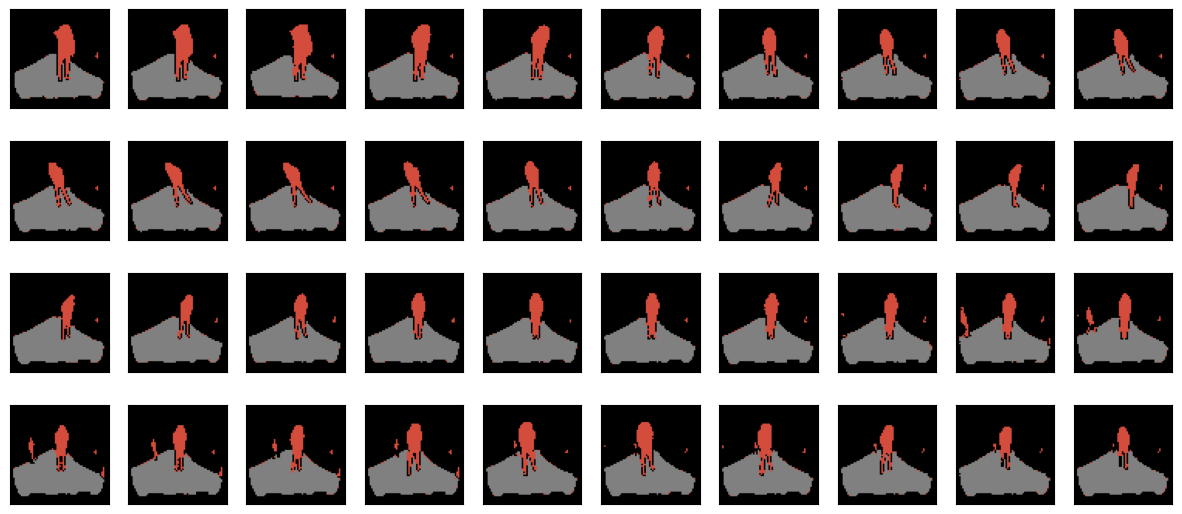

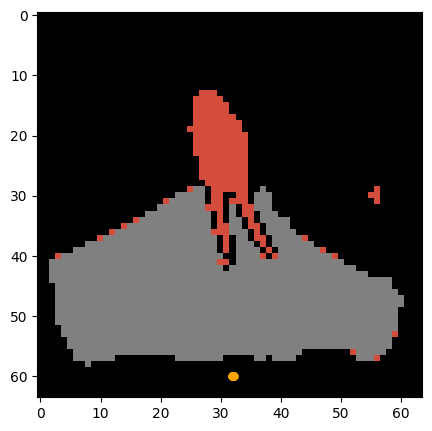

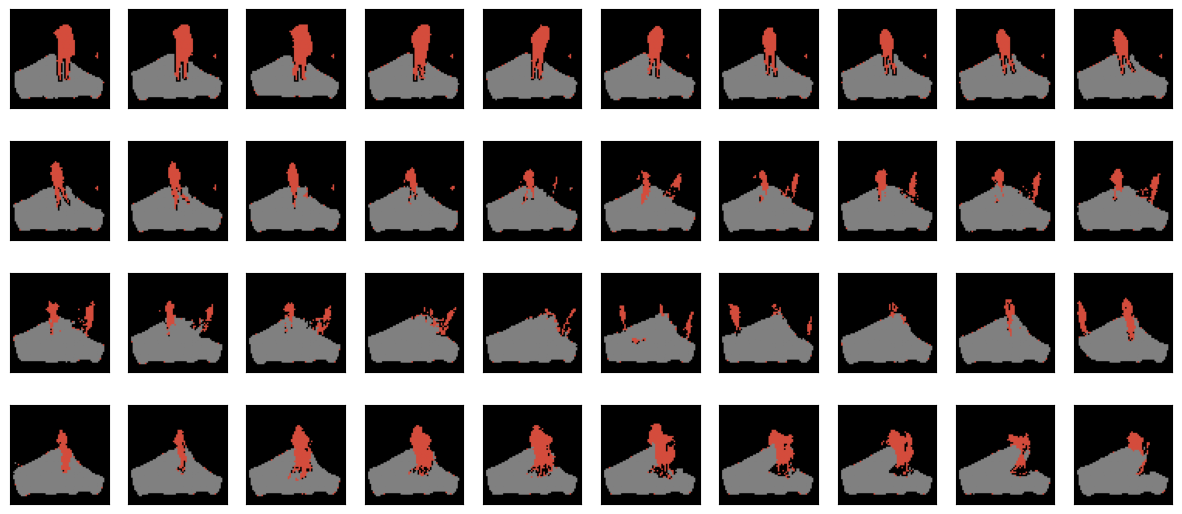

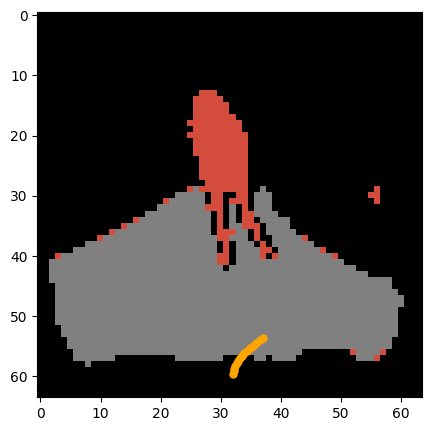

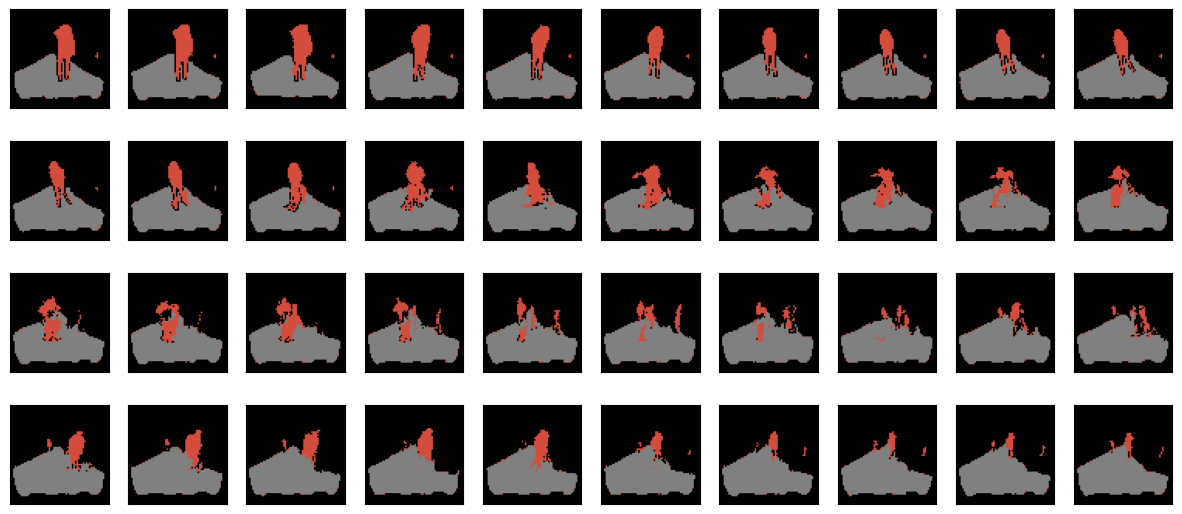

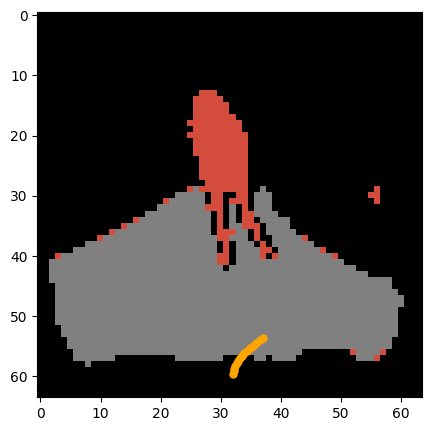

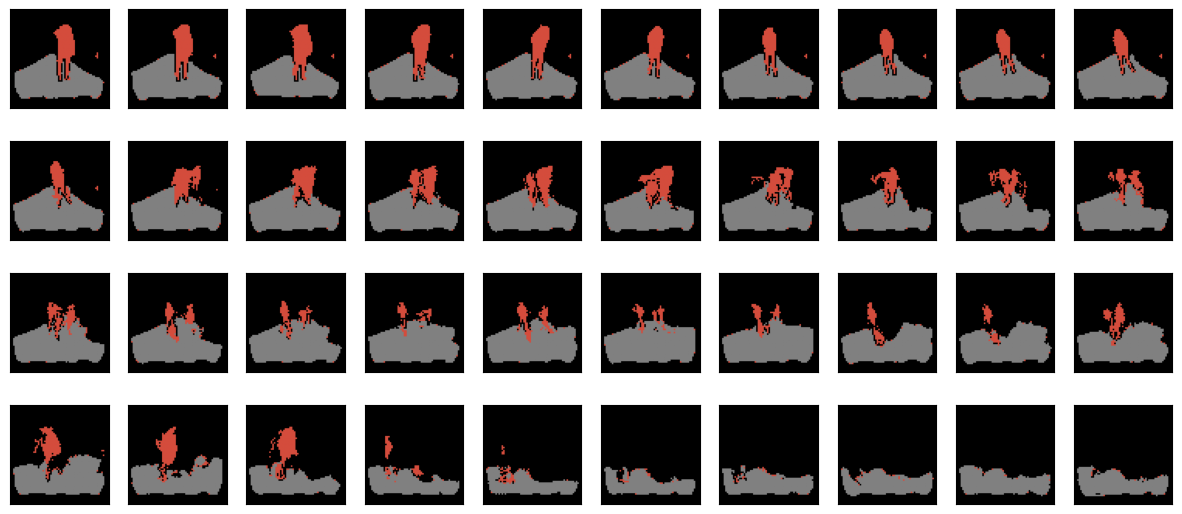

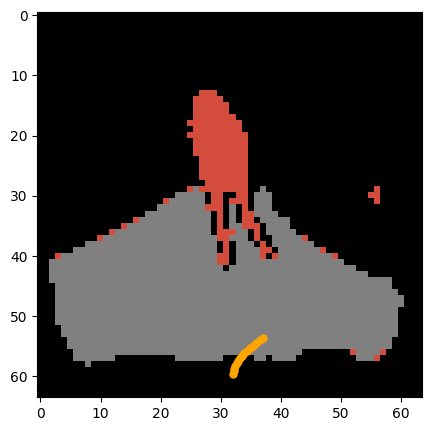

In [32]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray2color, gray3c_2color
import time

# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241006_mul_fps_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_vae_3c_seg/VDT_20250203_ATR_1F_3F_seg_3c_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_vae_3c_seg/VDT_20250210_testdata_ATR_1F_3F_seg_3c_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'


ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

idx=24980
# Pick a sample in the dataset
# memo: 20241031_data 300, 475, 1020， 8000, 12318, 12949, 13180, 13344, 13348, 14000, 19016, 19206, 24980, 28000, 28800
# test: 1700, 2200, 2300
r = 3
vis_id = 0 # the index for visualization, default = 0
pred_num = 3 # The number of multiple predictions
frame_t = 10

test = True
batch, vid_idx, path = valid_dataset[idx]
print(vid_idx, path)
batch, mot = dict.values(batch)

mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
start_time = time.time()

vid = batch.to(DEVICE)
vid = vid.view(-1,64,64,9)
vid_obstacle = vid[:,:,:,0] + vid[:,:,:,1] + vid[:,:,:,3] + vid[:,:,:,4] + vid[:,:,:,5]
vid_human = vid[:,:,:,6]
vid_floor = vid[:,:,:,7]
vid = torch.cat((vid_obstacle.unsqueeze(3), vid_human.unsqueeze(3), vid_floor.unsqueeze(3)), dim=3).permute(0,3,1,2)

enc_vid = vae.encode(vid).latent_dist.sample()
enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

a = enc_vid.to(DEVICE)
b = mot.to(DEVICE)
rec_vid_list = []
rec_mot_list = []
dec_vid_list = []

dec_vid_list.append(vid.permute(0,2,3,1))
rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))

################ Original image #############################
batch = batch.permute(0,3,1,2)
if rgb:
    batch_rgb = batch
else:
    batch_rgb = gray2color(batch)
    batch_rgb = torch.clamp(batch_rgb, 0,1)

# rec_vid_list.append(batch_rgb.permute(0,2,3,1))
visual_vid_mmot(gray3c_2color(vid).permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

if test:
    diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
    diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

# Choose a mask type from 0 to 2
# 0: prediction 1: backward 2: interpolation, t means the current frame
mask_vid, mask_motion, _ = mask_generator(diff_a,diff_b, idx=0, t=frame_t)

##################### Mask the video or not ##############################
# mask_vid = torch.zeros_like(diff_a)
###########################################################################

# print(mask_vid[0,4])
a = a.repeat(pred_num,1,1,1,1)
b = b.repeat(pred_num,1,1)
############################################################
mask_motion = torch.zeros_like(diff_b)
b = torch.tensor([[0.1,-0.1]])
b = b.repeat(1,args.sequence_length,1).repeat(pred_num,1,1).to(DEVICE)
############################################################
diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)


with torch.no_grad():
    rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
    
rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)

repeat_lf_vid = vid.clone()
repeat_lf_vid[10:] = vid[10].clone()
# print(abs(torch.mean(repeat_lf_vid - vid)))
repeat_lf_vid = repeat_lf_vid.repeat(pred_num,1,1,1,1)

################ Decode image #############################
for i in range(pred_num):  
    rec_mot_list.append(rec_mot[i]) 
    # print(rec_vid[i].permute(0,2,3,1)[0,5,0])
    dec_vid = vae.decode(rec_vid[i]).sample
    # dec_vid_list.append(repeat_lf_vid[i].permute(0,2,3,1))

    dec_vid_list.append(dec_vid.permute(0,2,3,1))
    # print(dec_vid.permute(0,2,3,1)[0,0,0])
    if rgb:
        dec_rgb = torch.clamp(dec_vid, 0,1).permute(0,2,3,1)
    else:
        dec_rgb = gray3c_2color(dec_vid)
        dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
    rec_vid_list.append(dec_rgb)
est_time = time.time() - start_time
# print(len(rec_mot_list))
################ Select image (Naive selection) #############################
for t in range(pred_num):
    print(rec_vid_list[t].shape)
    end_x,end_y = visual_vid_mmot(rec_vid_list[t], [rec_mot_list[t+1]], rgb=True, is_road=True, grid=False, frame_t=frame_t)
    end_x = int(end_x.numpy())
    end_y = int(end_y.numpy())
    # print(end_x, end_y)
    xx, yy = torch.meshgrid(torch.arange(args.resolution), torch.arange(args.resolution), indexing="ij")
    detect_mask = ((xx-end_y)**2 +(yy-end_x)**2) <= r **2
    detected_area = rec_vid_list[t][7][detect_mask]
    # Check the end point is on the floor
    result = torch.all(detected_area == 128/255)
    print(result)

print("estimate time:", est_time)



In [50]:
from eval_3c.utils import manhattan_dist

manhattan_distance, _ = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim, vis_list = [False, False, False], pooled=True)


Frame 1 Manhattan Distances: {'background': tensor(0.1046), 'Human': tensor(0.0276), 'Floor': tensor(0.0954)}
Frame 2 Manhattan Distances: {'background': tensor(0.1105), 'Human': tensor(0.0437), 'Floor': tensor(0.1046)}
Frame 3 Manhattan Distances: {'background': tensor(0.0913), 'Human': tensor(0.0292), 'Floor': tensor(0.0879)}


### Human Channel extract

4
tensor(True, device='cuda:0')
tensor(True, device='cuda:0')
tensor(True, device='cuda:0')
tensor(True, device='cuda:0')


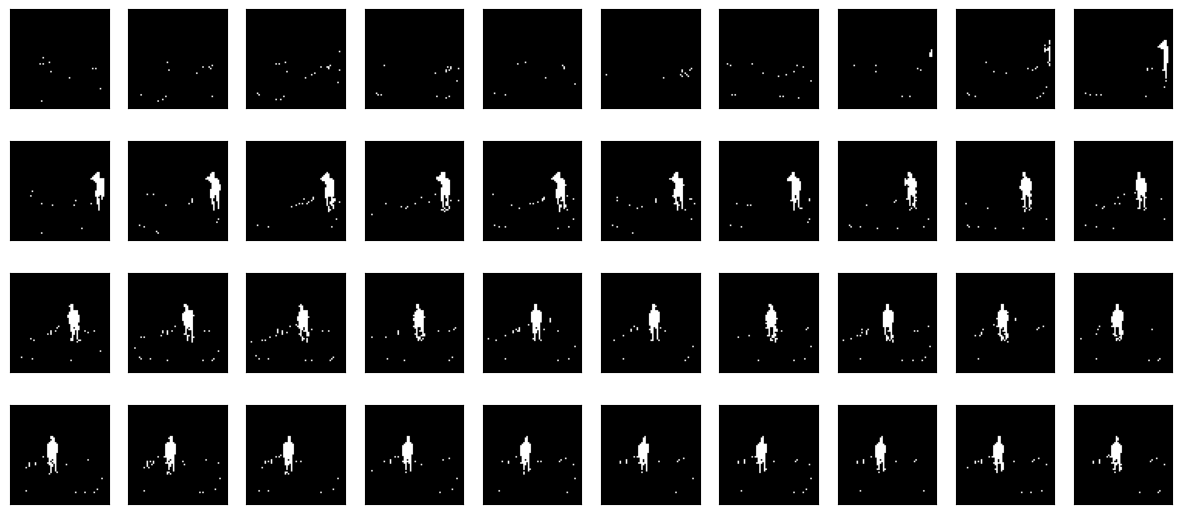

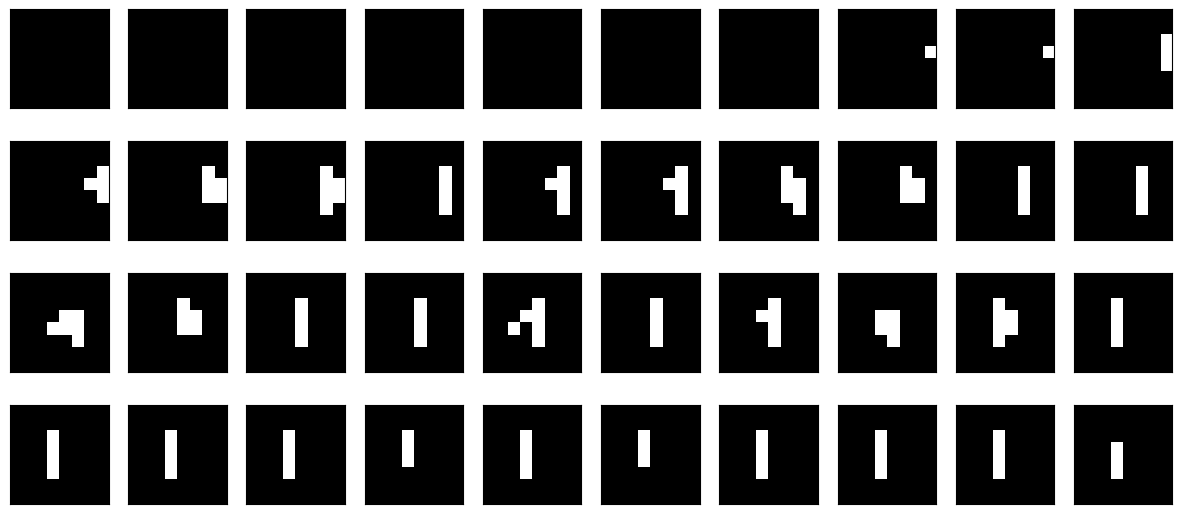

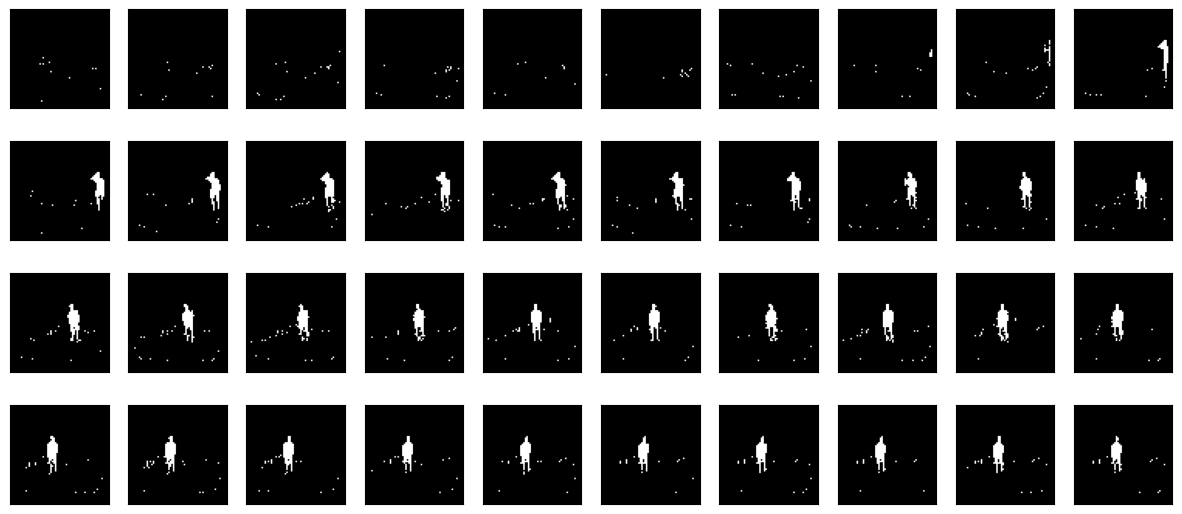

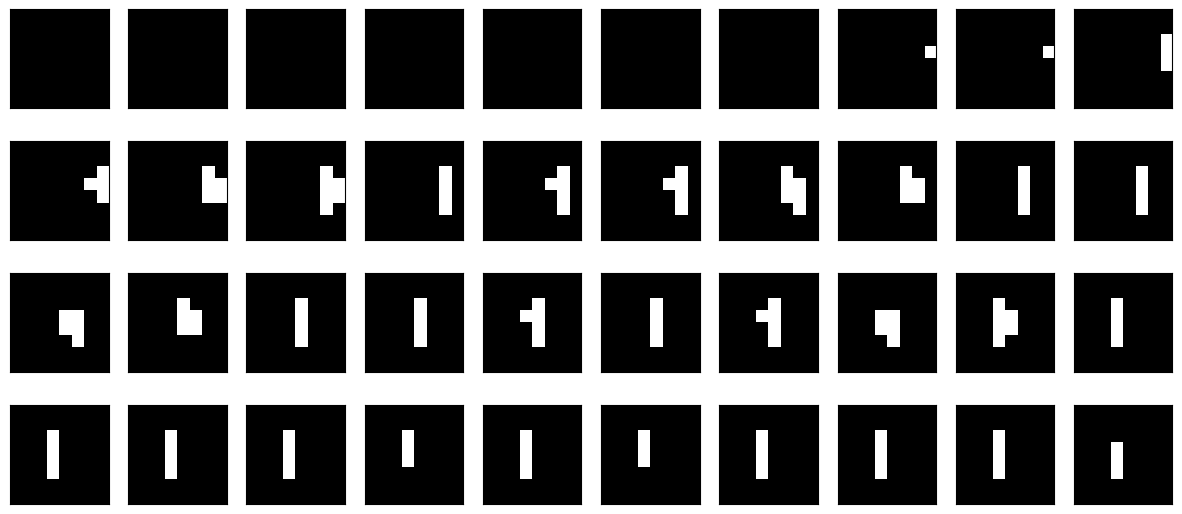

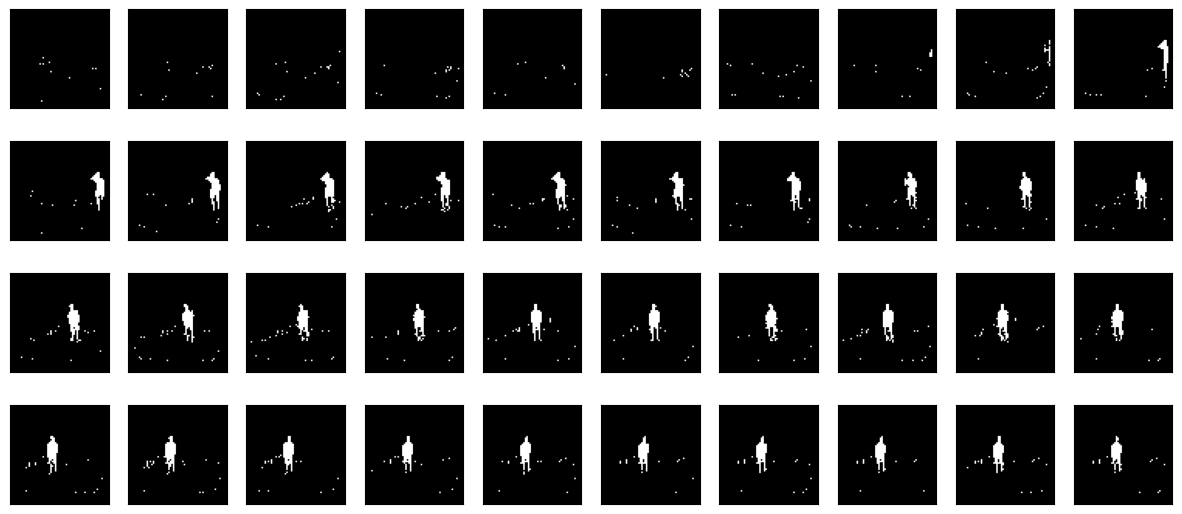

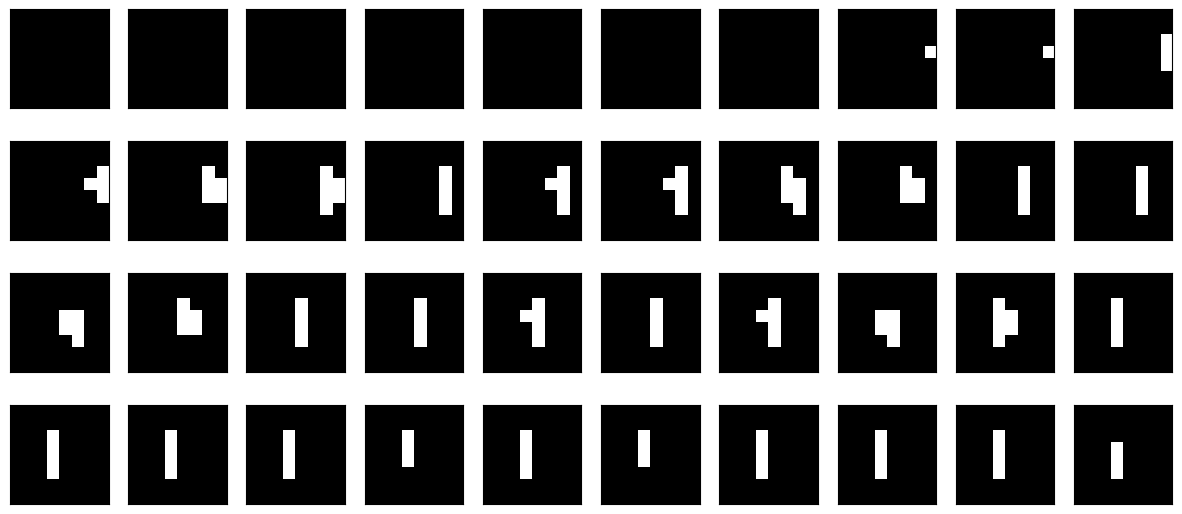

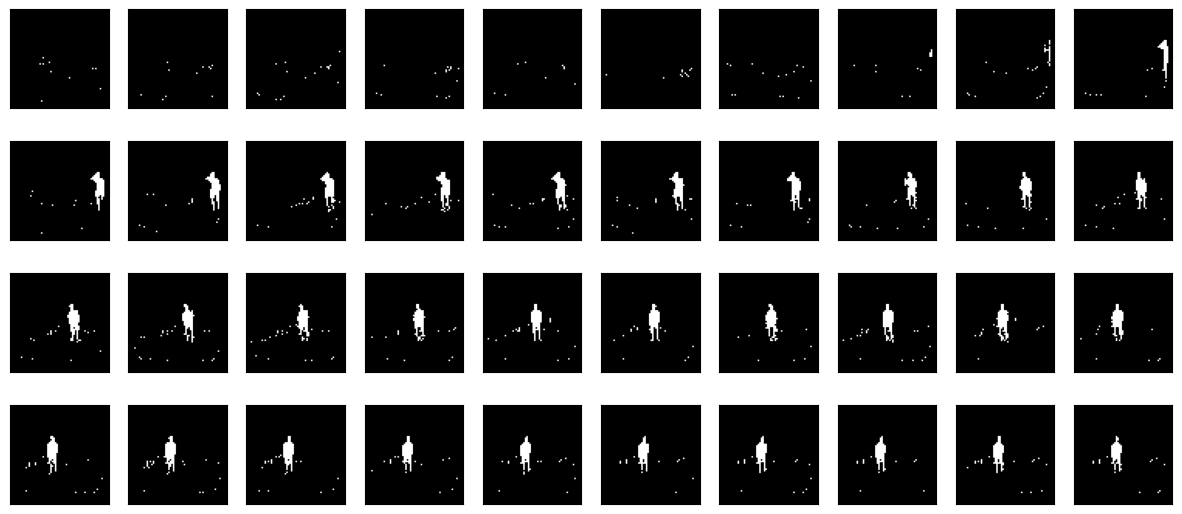

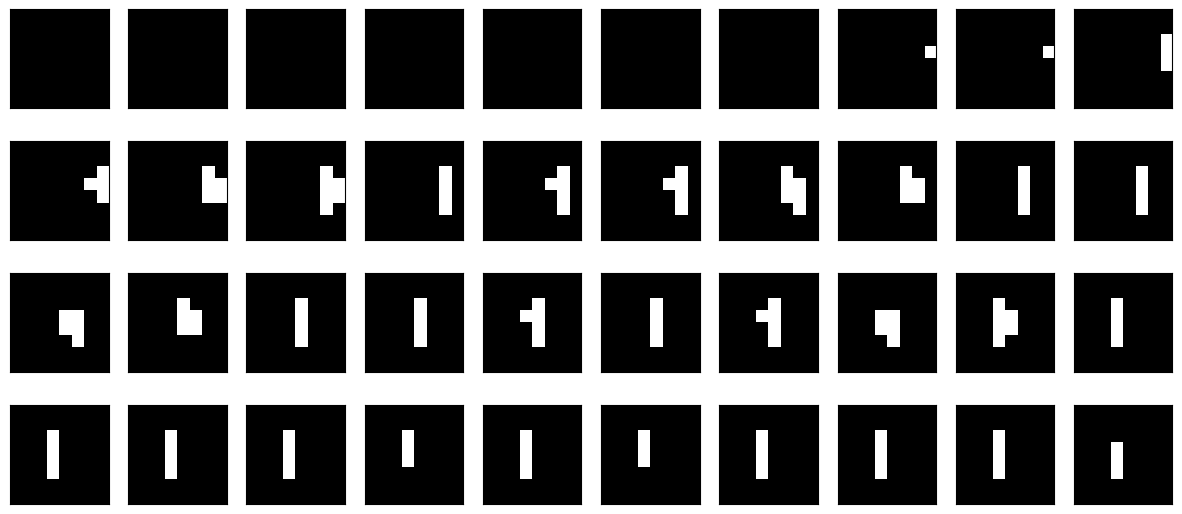

In [8]:
from utils import visual_img_each_channel
import torch.nn.functional as F
from eval_3c.utils import is_human

print(len(dec_vid_list))
for t in range(pred_num + 1):
    dec_vid = dec_vid_list[t]
    mot = rec_mot_list[t]

    min_val = dec_vid.min()
    max_val = dec_vid.max()
    video_normalized = (dec_vid - min_val) / (max_val - min_val)
    print(is_human(video_normalized.unsqueeze(0)))

    bg_ch = video_normalized[:,:,:,0]
    human_ch = video_normalized[:,:,:,1]
    floor_ch = video_normalized[:,:,:,2]

    human_ch = (human_ch > 0.60).float() 
    bg_ch = (bg_ch > 0.60).float() 
    floor_ch = (floor_ch > 0.60).float()
    pooled_human = F.avg_pool2d(human_ch, kernel_size=8, stride=8)
    threshold = 0.1
    pooled_human = (pooled_human > threshold).float()
    # print(pooled_human[0])
    
    visual_img_each_channel(human_ch.unsqueeze(0), mot_viz=False)
    visual_img_each_channel(pooled_human.unsqueeze(0), mot_viz=False)
    # visual_vid_mmot_each_channel(dec_vid.reshape(1,args.sequence_length,64,64,3), [mot], channel = 1, mot_viz=False, grid=False, frame_t=frame_t)



### Entropy Calculation

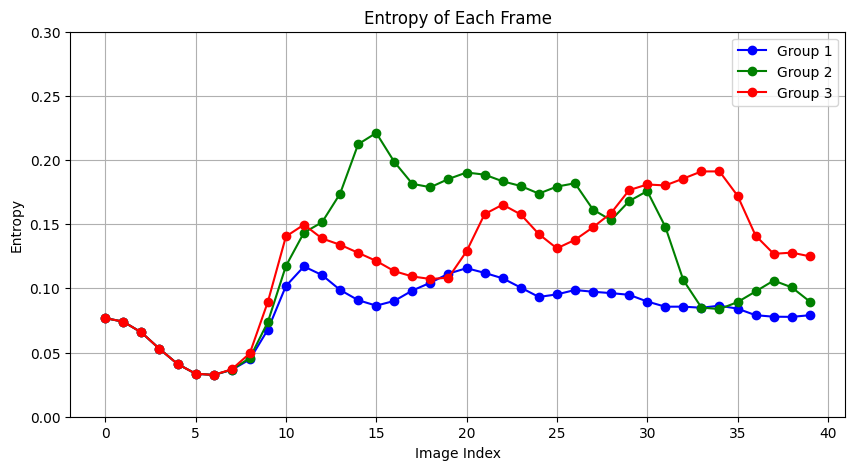

In [28]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

image_entropy_list = []
for decoded_output in dec_vid_list:
    prob = F.softmax(decoded_output[:,:,:,:], dim=-1)
    pixel_entropy = -torch.sum(prob * torch.log(prob + 1e-10), dim=-1)
    image_entropy = pixel_entropy.mean(dim=(1,2))
    image_entropy_list.append(image_entropy)

colors = ['b', 'g', 'r','y', 'c', 'k']
labels = ['Group 1', 'Group 2', 'Group 3', 'Group 4', 'Group 5','Group 6']

plt.figure(figsize=(10, 5))
for i in range(len(image_entropy_list)):
    smoothed_data = gaussian_filter1d(image_entropy_list[i].cpu().numpy(), sigma=1)  # 高斯滤波
    plt.plot(smoothed_data, marker='o', linestyle='-', color=colors[i], label=labels[i])

plt.ylim(0, 0.3)
plt.xlabel("Image Index")
plt.ylabel("Entropy")
plt.title("Entropy of Each Frame")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
image2_entropy_list = []

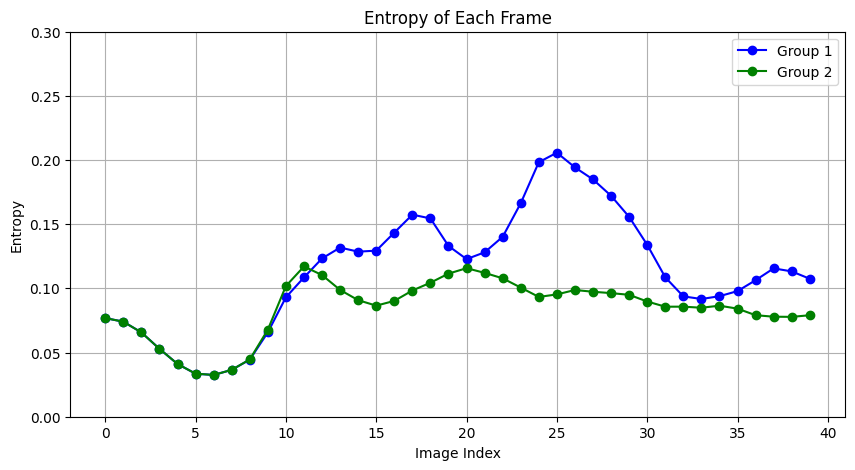

In [29]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

decoded_output = dec_vid_list[0]
prob = F.softmax(decoded_output, dim=-1)
pixel_entropy = -torch.sum(prob * torch.log(prob + 1e-10), dim=-1)
image_entropy = pixel_entropy.mean(dim=(1,2))
image2_entropy_list.append(image_entropy)

colors = ['b', 'g', 'r']
labels = ['Group 1', 'Group 2', 'Group 3']
comb_ent = image2_entropy_list
plt.figure(figsize=(10, 5))
for i in range(len(comb_ent)):
    smoothed_data = gaussian_filter1d(comb_ent[i].cpu().numpy(), sigma=1)  # 高斯滤波
    plt.plot(smoothed_data, marker='o', linestyle='-', color=colors[i], label=labels[i])

plt.ylim(0, 0.3)
plt.xlabel("Image Index")
plt.ylabel("Entropy")
plt.title("Entropy of Each Frame")
plt.legend()
plt.grid(True)
plt.show()

### Variance Calculation

torch.Size([40, 64, 64, 3])


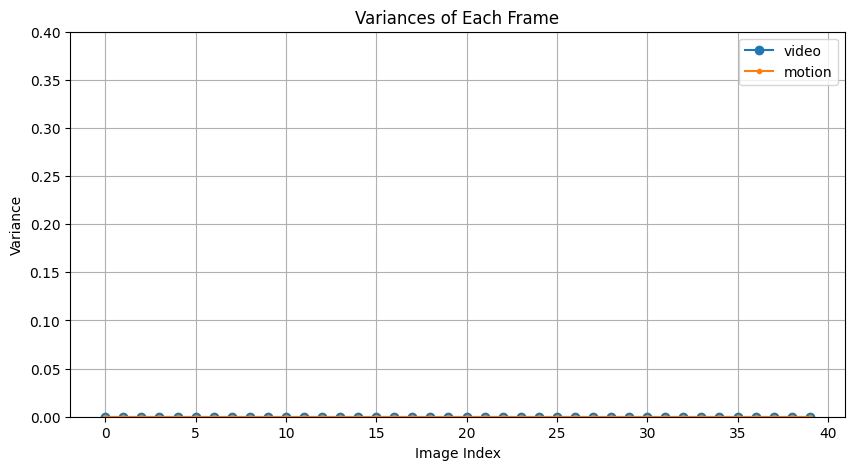

In [11]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

videos = torch.stack(dec_vid_list, axis=0)
motions = torch.stack(rec_mot_list, axis = 0)
variance_vid = torch.var(videos, axis=0)
variance_mot = torch.var(motions, axis=0)

print(variance_vid.shape)
variance_vid = variance_vid.mean(dim=(1,2,3))
variance_mot = variance_mot.mean(dim=(1))

# 计算累计方差
variance_vid = torch.cumsum(variance_vid, dim=0)
variance_mot = torch.cumsum(variance_mot, dim=0)

plt.figure(figsize=(10, 5))

smoothed_data_vid = gaussian_filter1d(variance_vid.cpu().numpy(), sigma=1)  # 高斯滤波
smoothed_data_mot = gaussian_filter1d(variance_mot.cpu().numpy(), sigma=1)  # 高斯滤波

plt.plot(smoothed_data_vid, marker='o', linestyle='-', label = 'video')
plt.plot(smoothed_data_mot, marker='.', linestyle='-', label = 'motion')

plt.ylim(0, 0.4)
plt.xlabel("Image Index")
plt.ylabel("Variance")
plt.title("Variances of Each Frame")
plt.legend()
plt.grid(True)
plt.show()

## 5. Visualization

### Load the dataset

In [11]:
data_origin_path = 'dataset/2024-10-31_xacti_5fps_origin'
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(data_origin_path, args.sequence_length,rgb=True, train=True, resolution=args.resolution)

# dataloader for the trainning
o_dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

# dataloader for the evaluation
o_dataset = Dataset(data_origin_path, args.sequence_length, rgb=True, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

metadata exists in: dataset/2024-10-31_xacti_5fps_origin/train/metadata_40.pkl


metadata exists in: dataset/2024-10-31_xacti_5fps_origin/test/metadata_40.pkl


metadata exists in: dataset/2024-10-31_xacti_5fps_origin/train/metadata_40.pkl
730 dataset/2024-10-31_xacti_5fps_origin/train/data_2024-10-24-16_54_21_3m_in_233_sec/17.mp4


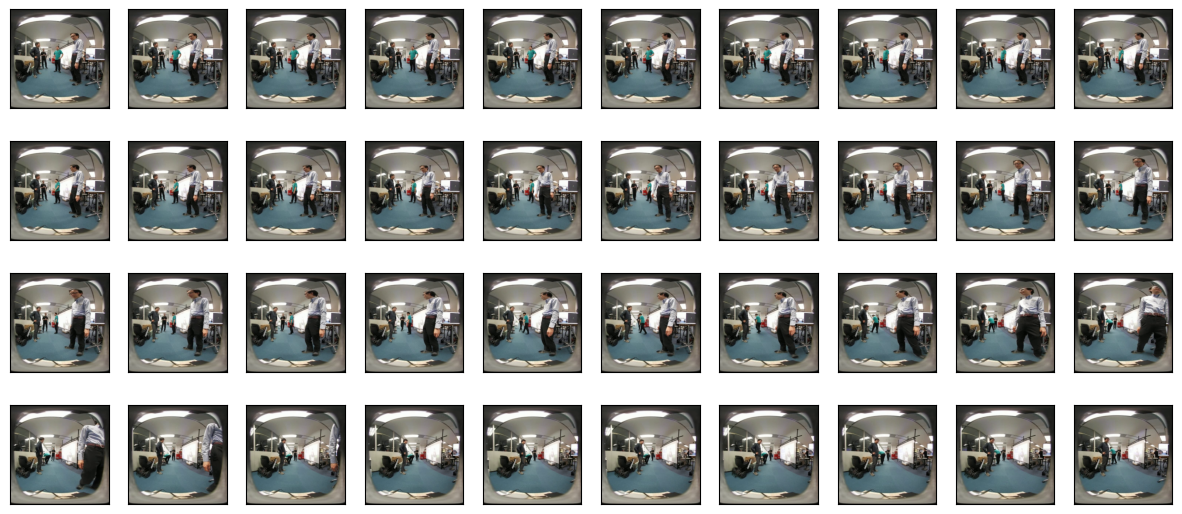

<Figure size 2000x500 with 0 Axes>

In [52]:
o_valid_dataset = Dataset(data_origin_path, args.sequence_length, rgb=True, train=True, resolution=256)
# memo: data20240807 1720, 210, 300, 520, 500, 3500
batch, vid_idx, path = o_valid_dataset[idx]
batch, mot = dict.values(batch)
mot = mot.permute(1,0).reshape(1,args.sequence_length,2)
print(vid_idx, path)
visual_vid_mmot(batch, mot, rgb=True,mot_viz=False, grid=False)

### Save the video

In [53]:
import cv2
import numpy as np

# 假设 blended_video 是混合后的帧，形状为 (8, 64, 64, 3)

def save_video(frames, motion, output_path, fps=10):
    # 获取帧的宽度和高度（假设所有帧大小一致）
    height, width, _ = frames[0].shape
    
    # 定义视频编码器, 选择一个合适的编码器，例如 MJPG 或 MP4
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')

    # 创建 VideoWriter 对象
    out = cv2.VideoWriter(output_path, fourcc, fps, (256, 256))
    start_x, start_y = width // 2, height - 5  # 从视频中心开始

    # 将每一帧写入视频
    for i in range(args.sequence_length - frame_t):
        frame = frames[i]
        speed = motion[i, 0]  # 前后的移动速度
        angle = motion[i, 1]  # 转角（弧度）
        # 计算箭头的结束位置
        if (abs(speed) < 0.1) and (abs(angle)<0.1):
            end_x = int(start_x)
            end_y = int(start_y)  
        # elif abs(angle) < 0.1:
        #     end_x = int(start_x)
        #     end_y = int(start_y - 5 * np.cos(angle))  
        else:
            # print(np.sin(angle))
            end_x = int(start_x - 30 * np.sin(angle))
            end_y = int(start_y - 25 * np.cos(angle))  
        # end_x = int(start_x + speed * 1 * np.sin(angle))  
        # end_y = int(start_y + speed * 1 * np.cos(angle))  
        # print(3 * np.sin(angle))
        # print(end_y)

        # 绘制箭头
        arrow_color = (0, 1, 0)  # 绿色箭头
        cv2.arrowedLine(frame, (start_x, start_y), (end_x, end_y), arrow_color, thickness=2, tipLength=0.5)

        # 更新起始位置为当前结束位置
        # start_x, start_y = end_x, end_y

        if frame.dtype == np.float64:
            frame = (frame * 255).astype(np.uint8)
        # 如果帧是 RGB 格式，需要转换为 BGR 格式
        frame_bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
        frame_bgr = cv2.resize(frame_bgr,(256,256))
        # 写入视频文件
        out.write(frame_bgr)
    
    # 释放 VideoWriter 对象
    out.release()
    print(f"视频已保存为 {output_path}")

########## choose one video generated by model ####################
index = 2
vid = rec_vid_list[index]
print((rec_mot_list[0].shape))
mot = rec_mot_list[index].squeeze()[:].cpu().numpy()
print(mot.shape)
bg_frame = np.float64(batch[frame_t-1].numpy())

########## Resize the generated video to (256,256) ####################
later_frames = vid[:].cpu().numpy()
resized_frames = []
print(later_frames.shape)
for frame in later_frames:  # 逐帧处理
    resized_frame = np.float64(cv2.resize(frame, (256, 256)))  # 调整为 256x256
    resized_frames.append(resized_frame)

# 转换为 NumPy 数组形式，形状为 (8, 256, 256, channels)
resized_frames = np.array(resized_frames)

alpha = 0
blended_frames = []

for i in range(args.sequence_length):
    # 将背景帧与当前帧进行混合
    blended_frame = cv2.addWeighted(bg_frame, alpha, resized_frames[i], 1- alpha, 0)
    blended_frames.append(blended_frame)

blended_video = np.array(blended_frames)
save_video(blended_video, mot, 'output_video.mp4', fps=5)


# !echo "y" | ffmpeg -i output_video.mp4 -vf "fps=10,scale=256:-1:flags=lanczos" -ss 00:00:00 -to 00:00:02 -pix_fmt yuv420p sample_1.gif
!echo "y" | ffmpeg -i output_video.mp4 -c:v libx264 -crf 23 -preset fast -ss 00:00:00 -to 00:00:02 -pix_fmt yuv420p video1_c.mp4
!echo "y" | ffmpeg -i output_video.mp4 -c:v libx264 -crf 23 -preset fast -ss 00:00:02 -to 00:00:08 -pix_fmt yuv420p video1_t.mp4

!rm output_video.mp4

torch.Size([1, 40, 2])
(40, 2)
(40, 64, 64, 3)
视频已保存为 output_video.mp4
ffmpeg version 3.4.11-0ubuntu0.1 Copyright (c) 2000-2022 the FFmpeg developers
  built with gcc 7 (Ubuntu 7.5.0-3ubuntu1~18.04)
  configuration: --prefix=/usr --extra-version=0ubuntu0.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --enable-gpl --disable-stripping --enable-avresample --enable-avisynth --enable-gnutls --enable-ladspa --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librubberband --enable-librsvg --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvorbis --enable-libvpx --enable-libwavpack --enable

In [28]:
from IPython.display import Video,clear_output
clear_output(wait=True)
Video("video1_t.mp4")
